# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *I want to predict whether a breast mass is malignant or benign using 30 numeric measurements taken from digitized images of fine-needle aspirates. This is a supervised binary classification problem because every sample already has a known label. The costlier mistake is a false negative, where a malignant tumor is labeled benign, since the patient’s treatment could be delayed. I will judge the model mainly by recall for the malignant class, together with ROC-AUC and accuracy.*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [56]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [57]:
data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names),
      "-> 0 = malignant, 1 = benign")

df.head()

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [58]:
print(df.shape)
print(df.dtypes.value_counts())
display(df.head())

(569, 31)
float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [59]:
print(df["target"].value_counts())
print((df["target"].value_counts(normalize=True) * 100).round(1))

target
1    357
0    212
Name: count, dtype: int64
target
1    62.7
0    37.3
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [60]:
display(df.describe().T)
print(df.drop(columns="target").skew().sort_values(ascending=False).head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [61]:
corr = df.corr()["target"].drop("target").sort_values()
print(corr.head(5))
print(corr.tail(5))

worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *The classes are mildly imbalanced (about 63% benign, 37% malignant), so accuracy alone can look good even if the model misses malignant cases. I will also use recall for the malignant class and ROC-AUC. Many features are right-skewed (e.g., area, concavity, and the error features), so scaling or transforms will help distance-based and linear models such as KNN, SVM and logistic regression.*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

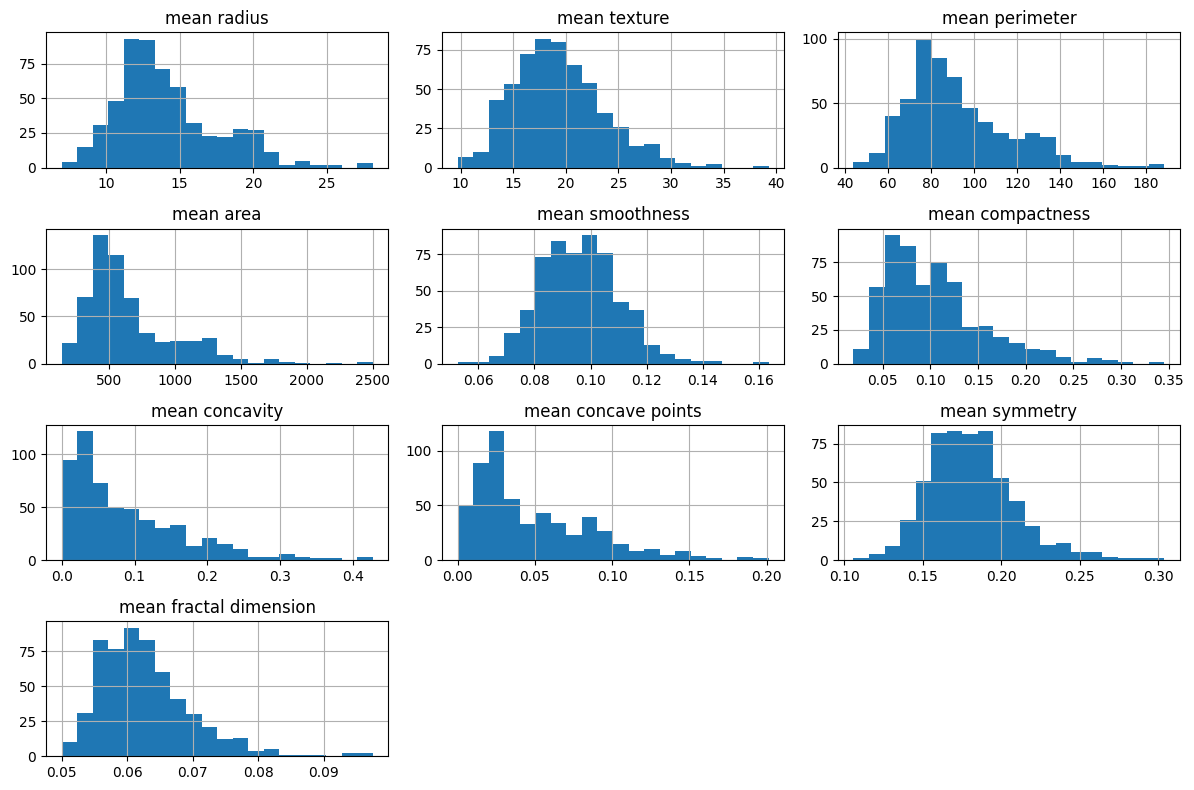

In [62]:
import matplotlib.pyplot as plt

df.filter(like="mean").hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

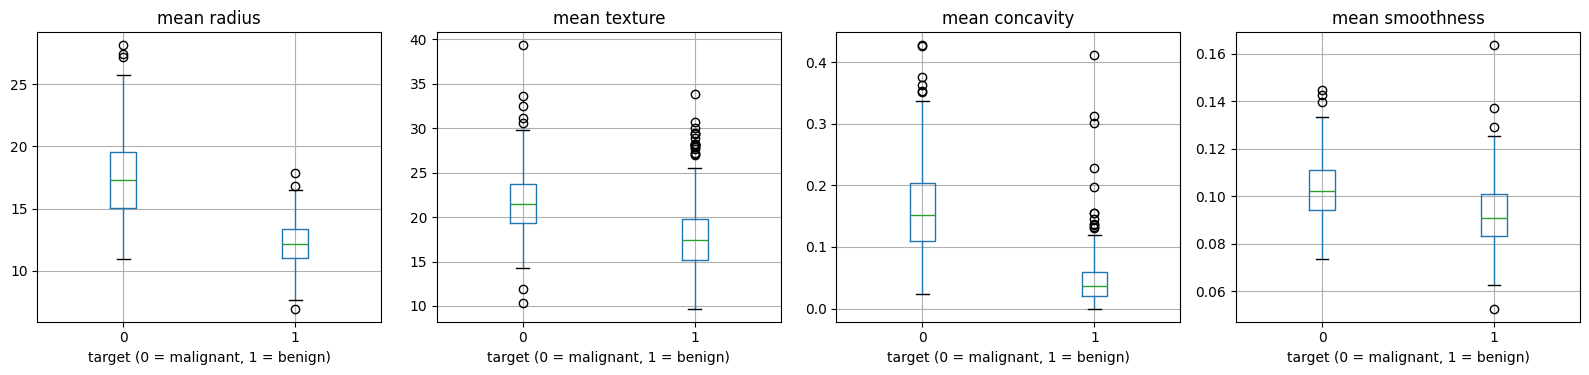

In [63]:
import matplotlib.pyplot as plt

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, features):
    df.boxplot(column=f, by="target", ax=ax)
    ax.set_title(f)
    ax.set_xlabel("target (0 = malignant, 1 = benign)")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

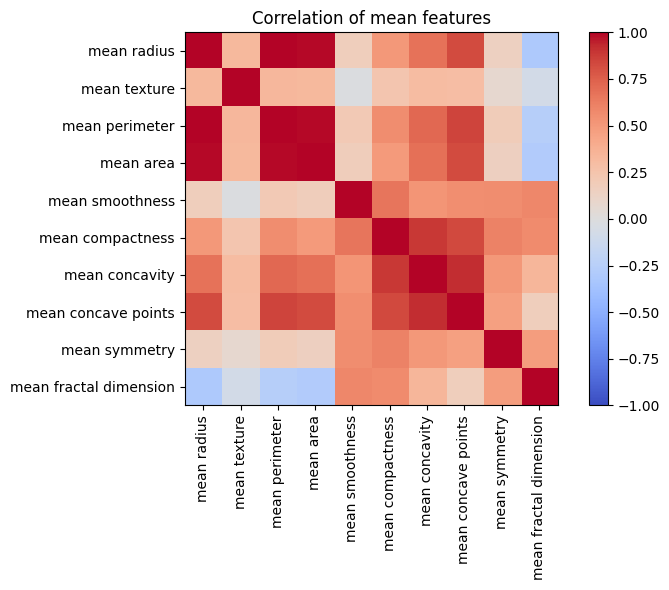

In [64]:
mean_cols = df.filter(like="mean").columns
c = df[mean_cols].corr()
plt.figure(figsize=(8, 6))
plt.imshow(c, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(mean_cols)), mean_cols, rotation=90)
plt.yticks(range(len(mean_cols)), mean_cols)
plt.title("Correlation of mean features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

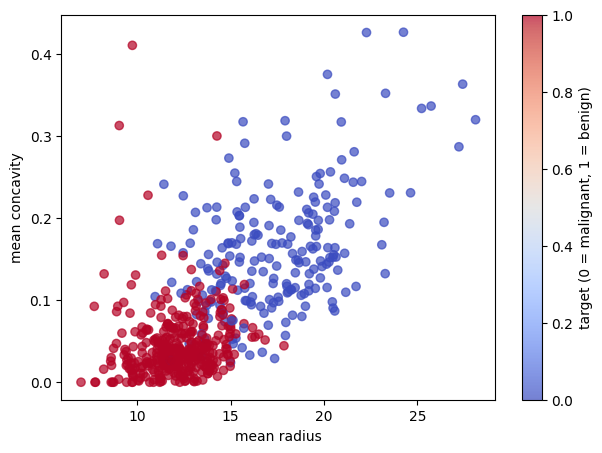

In [65]:
plt.figure(figsize=(7, 5))
sc = plt.scatter(df["mean radius"], df["mean concavity"],
                 c=df["target"], cmap="coolwarm", alpha=0.7)
plt.xlabel("mean radius")
plt.ylabel("mean concavity")
plt.colorbar(sc, label="target (0 = malignant, 1 = benign)")
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *Radius, perimeter and area are highly redundant (they are almost perfectly correlated), and concavity, concave points and compactness also move together. The features that separate the classes best are concave points, perimeter, radius, area and concavity. Smoothness and fractal dimension overlap the most between classes.*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [66]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [67]:
X = df.drop(columns="target")

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).sum()
print(outliers.sort_values(ascending=False).head(10))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *No, I would not delete them. The dataset is small (569 rows), and the outliers are likely real large tumors, which are exactly the malignant cases the model must learn from. Deleting them would remove useful information and could bias the model. Scaling or robust models can handle them instead.*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [68]:
import numpy as np

corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [col for col in upper.columns if (upper[col] > 0.95).any()]
print(high_corr)

['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [69]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# Define the target variable y
y = df["target"]

# Fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
skb = SelectKBest(score_func=f_classif, k=10).fit(X, y)
scores = pd.Series(skb.scores_, index=X.columns).sort_values(ascending=False)

print("Top 10 features according to SelectKBest:")
print(scores.head(10))

kbest_features = list(scores.head(10).index)

Top 10 features according to SelectKBest:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [70]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale X since Logistic Regression is sensitive to feature magnitude
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit RFE
lr = LogisticRegression(max_iter=1000, random_state=7)
rfe = RFE(estimator=lr, n_features_to_select=10)
rfe.fit(X_scaled, y)

# Get selected feature names
rfe_features = list(X.columns[rfe.support_])

print("Features selected by RFE:")
print(rfe_features)

Features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

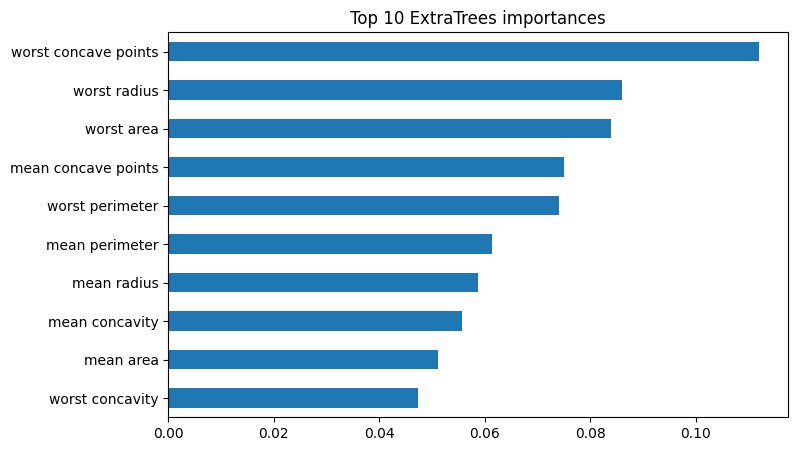

In [71]:
et = ExtraTreesClassifier(n_estimators=200, random_state=7).fit(X, y)
imp = pd.Series(et.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 ExtraTrees importances")
plt.show()
et_features = list(imp.head(10).index)

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [72]:
from collections import Counter
votes = Counter(kbest_features + rfe_features + et_features)
selected = [f for f, v in votes.items() if v >= 2]
print(len(selected), selected)

10 ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=7)

**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [74]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

std = StandardScaler().fit(X_train)
mm = MinMaxScaler().fit(X_train)
Xs = pd.DataFrame(std.transform(X_train), columns=X_train.columns)
Xm = pd.DataFrame(mm.transform(X_train), columns=X_train.columns)
print(Xs.iloc[:, :4].agg(["mean", "std"]).round(3))
print(Xm.iloc[:, :4].agg(["min", "max"]).round(3))

      mean radius  mean texture  mean perimeter  mean area
mean        0.000        -0.000          -0.000     -0.000
std         1.001         1.001           1.001      1.001
     mean radius  mean texture  mean perimeter  mean area
min          0.0           0.0             0.0        0.0
max          1.0           1.0             1.0        1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [75]:
import numpy as np
from sklearn.decomposition import PCA

pca = PCA().fit(std.transform(X_train))
cum = np.cumsum(pca.explained_variance_ratio_)
n_comp = int(np.argmax(cum >= 0.95) + 1)
print("Components for 95% variance:", n_comp)

Components for 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [76]:
seed = 7

models = {
    "LR": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(),
}

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [77]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

raw = spot_check(models, X_train, scale=False)
scaled = spot_check(models, X_train, scale=True)
summary = pd.DataFrame({
    "raw": {k: v.mean() for k, v in raw.items()},
    "scaled": {k: v.mean() for k, v in scaled.items()},
}).round(4)
display(summary)

,raw,scaled
LR,0.9450,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *KNN, SVM and Logistic Regression benefit the most from scaling. KNN and SVM depend on distances, so features with large values (like area) dominate when unscaled, and logistic regression converges better on standardized data. CART and Naive Bayes are mostly unaffected, since trees split on thresholds and NB models each feature separately.*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [78]:
sel_scaled = spot_check(models, X_train[selected], scale=True)
comparison = pd.DataFrame({
    "all_scaled": summary["scaled"],
    "selected_scaled": {k: v.mean() for k, v in sel_scaled.items()},
}).round(4)
display(comparison)

,all_scaled,selected_scaled
LR,0.9823,0.9604
LDA,0.9472,0.9430
KNN,0.9649,0.9428
CART,0.9276,0.9253
NB,0.9320,0.9517
SVM,0.9758,0.9539


Feature selection did not really help. Most models scored slightly lower with the 10 selected features (for example LR dropped from 0.982 to 0.960 and SVM from 0.976 to 0.954), while Naive Bayes improved from 0.932 to 0.952. It makes the models simpler with fewer inputs, but with a small loss in accuracy.

**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

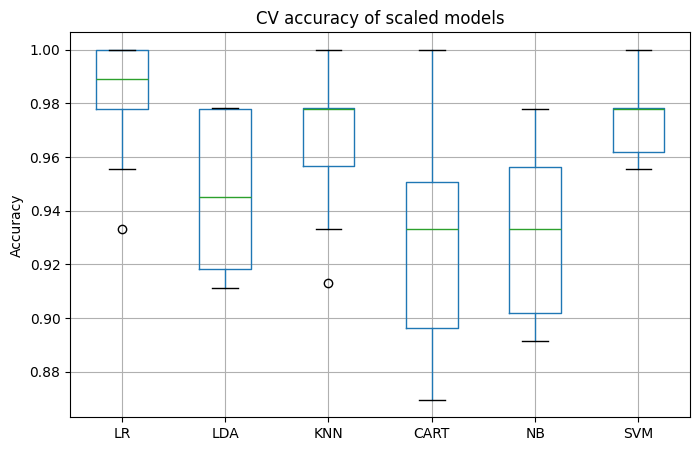

In [79]:
pd.DataFrame(scaled).boxplot(figsize=(8, 5))
plt.title("CV accuracy of scaled models")
plt.ylabel("Accuracy")
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [80]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

best_name = summary["scaled"].idxmax()
print("Best scaled model:", best_name)
best_model = Pipeline([("scale", StandardScaler()), ("model", models[best_name])])
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0),
}
cv_res = cross_validate(best_model, X_train, y_train, cv=kfold, scoring=scoring)
for k in scoring:
    print(k, round(cv_res[f"test_{k}"].mean(), 4), "+/-", round(cv_res[f"test_{k}"].std(), 4))

Best scaled model: LR
accuracy 0.9823 +/- 0.0218
roc_auc 0.9922 +/- 0.0107
recall_malignant 0.9647 +/- 0.0471


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [81]:
from sklearn.model_selection import GridSearchCV

svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])
svm_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"],
}
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=kfold, scoring="accuracy", n_jobs=-1)
svm_search.fit(X_train, y_train)
print(svm_search.best_score_, svm_search.best_params_)

0.9801932367149758 {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [82]:
knn_pipe = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])
knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
}
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=kfold, scoring="accuracy", n_jobs=-1)
knn_search.fit(X_train, y_train)
print(knn_search.best_score_, knn_search.best_params_)

0.9692753623188406 {'model__n_neighbors': 3, 'model__weights': 'uniform'}


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [83]:
ensembles = {
    "RF": RandomForestClassifier(n_estimators=200, random_state=seed),
    "ET": ExtraTreesClassifier(n_estimators=200, random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed),
}
ens_results = spot_check(ensembles, X_train, scale=False)
for k, v in ens_results.items():
    print(k, round(v.mean(), 4))

voting = VotingClassifier(
    [("svm", svm_search.best_estimator_),
     ("knn", knn_search.best_estimator_),
     ("rf", ensembles["RF"])],
    voting="hard")
voting_scores = cross_val_score(voting, X_train, y_train, cv=kfold, scoring="accuracy")
print("Voting", round(voting_scores.mean(), 4))

RF 0.9648
ET 0.9714
GBM 0.967
AB 0.9626
Voting 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [84]:
leaderboard = pd.Series({
    "SVM (tuned)": svm_search.best_score_,
    "KNN (tuned)": knn_search.best_score_,
    **{k: v.mean() for k, v in ens_results.items()},
    "Voting": voting_scores.mean(),
}).sort_values(ascending=False)
print(leaderboard.round(4))

SVM (tuned)    0.9802
Voting         0.9781
ET             0.9714
KNN (tuned)    0.9693
GBM            0.9670
RF             0.9648
AB             0.9626
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winner: SVM (tuned)
Test accuracy: 0.9649
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



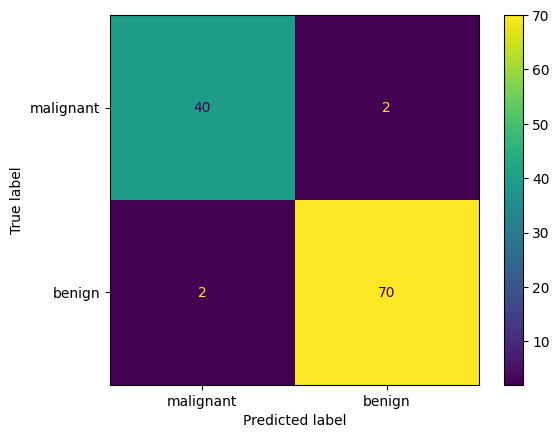

In [85]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_models = {
    **ensembles,
    "SVM (tuned)": svm_search.best_estimator_,
    "KNN (tuned)": knn_search.best_estimator_,
    "Voting": voting,
}
winner_name = leaderboard.index[0]
print("Winner:", winner_name)
final_model = all_models[winner_name]
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=data.target_names))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=data.target_names)
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [86]:
import joblib
joblib.dump(final_model, "final_model.joblib")
loaded = joblib.load("final_model.joblib")
print("Predictions:", loaded.predict(X_test)[:5])
print("Actual:     ", y_test.values[:5])
print("Same as before:", (loaded.predict(X_test) == pred).all())

Predictions: [0 0 1 0 1]
Actual:      [0 0 1 0 1]
Same as before: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

1.Leakage. If features are selected using the whole dataset, the selection has already “seen” the validation folds, so CV scores look better than they really are. To fix this, put SelectKBest inside the Pipeline (scaler → selector → model) so it is re-fitted only on the training part of each fold.

2.Metric choice. I would report recall for the malignant class (along with ROC-AUC and the confusion matrix). Accuracy alone is not enough because a missed cancer (false negative) is far more harmful than a false alarm, and accuracy hides which kind of error the model makes.

3.Model choice. A 0.3% difference is often within noise, so I would check the standard deviation across folds. If it is similar, I would choose the simpler, more interpretable and cheaper-to-train model (for example logistic regression over a large ensemble).

4.Generalization. With a smaller dataset, CV estimates become noisier and complex models overfit more easily. With a much more imbalanced dataset, accuracy becomes misleading, so I would use stratified splits, class weights or resampling, and metrics like recall, precision, F1 or PR-AUC.

5.Extension. With a new dataset, I would change the loading step (e.g., ARFF via scipy.io.arff), the cleaning (missing values, categorical encoding), the feature names, and possibly the metric and class labels. The pipeline and CV structure stay the same